In [20]:
import json, shutil
import yaml
import numpy as np
import kagglehub   
import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from pathlib import Path
from datetime import datetime, timezone
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image

In [21]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR      = PROJECT_ROOT / "data" / "raw"
KAGGLE_ID    = "moazawadali/plant-leaf-diseases"      
IMG_EXTS     = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_DIR    = PROJECT_ROOT / "data" / "splits"
FIG_DIR      = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw dir     :", RAW_DIR)

Project root: /home/ambitiousflow/projects/plant-diseases-classification
Raw dir     : /home/ambitiousflow/projects/plant-diseases-classification/data/raw


In [22]:
class DatasetDownloader:
    def __init__(self, kaggle_id: str, raw_dir: Path):
        self.kaggle_id = kaggle_id
        self.raw_dir   = Path(raw_dir)
        self.target    = self.raw_dir / kaggle_id.split("/")[-1]   

    def download(self, force: bool = False) -> Path:
        if self.target.exists() and any(self.target.iterdir()) and not force:
            print(f"[skip] Already downloaded: {self.target}")
            return self.target

        self.raw_dir.mkdir(parents=True, exist_ok=True)

        cache_path = Path(kagglehub.dataset_download(self.kaggle_id))
        print(f"[ok] Downloaded to cache: {cache_path}")

        if self.target.exists():
            shutil.rmtree(self.target)
        shutil.copytree(cache_path, self.target)

        self._write_provenance(cache_path)
        return self.target

    def _write_provenance(self, cache_path: Path) -> None:
        info = {
            "kaggle_id":     self.kaggle_id,
            "url":           f"https://www.kaggle.com/datasets/{self.kaggle_id}",
            "downloaded_at": datetime.now(timezone.utc).isoformat(),
            "cache_path":    str(cache_path),
            "local_path":    str(self.target),
        }
        (self.raw_dir.parent / "provenance.json").write_text(json.dumps(info, indent=2))

In [23]:
downloader   = DatasetDownloader(KAGGLE_ID, RAW_DIR)
DATASET_PATH = downloader.download()      
print("Dataset path:", DATASET_PATH)

[skip] Already downloaded: /home/ambitiousflow/projects/plant-diseases-classification/data/raw/plant-leaf-diseases
Dataset path: /home/ambitiousflow/projects/plant-diseases-classification/data/raw/plant-leaf-diseases


In [24]:
class DatasetValidator:
    
    def __init__(self, root: Path, img_exts: set, min_classes: int = 2):
        self.root        = Path(root)
        self.img_exts    = img_exts
        self.min_classes = min_classes
        self.class_root  = None     
        self.counts      = {}       

    def _images_in(self, folder: Path) -> list:
        return [p for p in folder.rglob("*") if p.suffix.lower() in self.img_exts]

    def _find_class_root(self) -> Path:
        candidates = [self.root] + sorted(
            (p for p in self.root.rglob("*") if p.is_dir()),
            key=lambda p: len(p.parts),
        )
        for folder in candidates:
            subs = [d for d in folder.iterdir() if d.is_dir() and self._images_in(d)]
            if len(subs) >= self.min_classes:
                return folder
        raise ValueError("No folder with class sub-folders containing images was found.")

    def validate(self) -> dict:
        assert self.root.exists(), f"Path not found: {self.root}"
        assert any(self.root.iterdir()), f"Path is empty: {self.root}"

        self.class_root = self._find_class_root()
        for d in sorted(self.class_root.iterdir()):
            if d.is_dir():
                self.counts[d.name] = len(self._images_in(d))

        empty = [c for c, n in self.counts.items() if n == 0]
        assert not empty, f"Empty classes: {empty}"

        return self.counts

    def report(self) -> None:
        total = sum(self.counts.values())
        print(f"Class root : {self.class_root}")
        print(f"Classes    : {len(self.counts)}")
        print(f"Images     : {total}\n")
        
        for cls, n in self.counts.items():
            print(f"  {cls:<35} {n:>6}  ({n / total:6.1%})")

        ratio = max(self.counts.values()) / min(self.counts.values())
        print(f"\nImbalance ratio (max/min): {ratio:.2f}")

In [25]:
validator = DatasetValidator(DATASET_PATH, IMG_EXTS)
validator.validate()
validator.report()
DATA_ROOT = validator.class_root

Class root : /home/ambitiousflow/projects/plant-diseases-classification/data/raw/plant-leaf-diseases/Plant_Leaf_Diseases
Classes    : 21
Images     : 40223

  Corn___Common_Rust                    1192  (  3.0%)
  Corn___Gray_Leaf_Spot                 1600  (  4.0%)
  Corn___Healthy                        1162  (  2.9%)
  Corn___Northern_Leaf_Blight           2900  (  7.2%)
  Grape___Black_Measles                 2271  (  5.6%)
  Grape___Black_Rot                     1180  (  2.9%)
  Grape___Healthy                       1305  (  3.2%)
  Grape___Leaf_Blight                   1076  (  2.7%)
  Potato___Early_Blight                 1000  (  2.5%)
  Potato___Healthy                      1152  (  2.9%)
  Potato___Late_Blight                  1000  (  2.5%)
  Tomato___Bacterial_Spot               2953  (  7.3%)
  Tomato___Early_Blight                 2074  (  5.2%)
  Tomato___Healthy                      2780  (  6.9%)
  Tomato___Late_Blight                  3235  (  8.0%)
  Tomato___Leaf_Mo

In [26]:
CFG       = yaml.safe_load((PROJECT_ROOT / "configs" / "base.yaml").read_text())
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SEED      = CFG["seed"]
IMG_SIZE  = CFG["img_size"]          
print(CFG)

{'seed': 42, 'img_size': 224, 'batch_size': 32, 'epochs': 15, 'optimizer': 'adam', 'lr_feature_extraction': 0.001, 'lr_finetune': 1e-05, 'early_stopping_patience': 5, 'split': {'train': 0.7, 'val': 0.15, 'test': 0.15}, 'early_stopping_min_delta': 0.001}


In [27]:
class DatasetSplitter:
    """Scans class folders, removes unreadable images, makes a stratified
    train/val/test split and saves it once, so every model sees the same data."""

    def __init__(self, data_root, img_exts, split, seed, out_dir):
        self.data_root = Path(data_root)
        self.img_exts  = img_exts
        self.split     = split                      
        self.seed      = seed
        self.out_dir   = Path(out_dir)

    def _scan(self) -> pd.DataFrame:
        classes = sorted(d.name for d in self.data_root.iterdir() if d.is_dir())
        rows = [
            {"path": str(p.relative_to(self.data_root)), "label": cls, "label_idx": idx}
            for idx, cls in enumerate(classes)
            for p in (self.data_root / cls).rglob("*")
            if p.suffix.lower() in self.img_exts
        ]
        return pd.DataFrame(rows)

    def _is_valid(self, rel_path: str) -> bool:
        try:
            with Image.open(self.data_root / rel_path) as im:
                im.verify()
            return True
        except Exception:
            return False

    def run(self) -> dict:
        df = self._scan()
        ok = df["path"].map(self._is_valid)
        print(f"Removed {(~ok).sum()} corrupted image(s) out of {len(df)}")
        df = df[ok].reset_index(drop=True)

        tmp_frac = self.split["val"] + self.split["test"]
        train, tmp = train_test_split(df, test_size=tmp_frac, stratify=df["label_idx"],random_state=self.seed)
        test_frac = self.split["test"] / tmp_frac
        val, test = train_test_split(tmp, test_size=test_frac, stratify=tmp["label_idx"],random_state=self.seed)

        self.out_dir.mkdir(parents=True, exist_ok=True)
        splits = {"train": train, "val": val, "test": test}
        for name, part in splits.items():
            part.to_csv(self.out_dir / f"{name}.csv", index=False)

        # Save class mapping + the root the relative paths refer to
        classes = df.drop_duplicates("label_idx").sort_values("label_idx")["label"].tolist()
        meta = {"classes": classes, "data_root": str(self.data_root)}
        (self.out_dir / "meta.json").write_text(json.dumps(meta, indent=2))
        return splits

In [28]:
splitter = DatasetSplitter(DATA_ROOT, IMG_EXTS, CFG["split"], SEED, SPLIT_DIR)
splits   = splitter.run()
summary = pd.DataFrame({k: v["label"].value_counts() for k, v in splits.items()})
print(summary, "\n", summary.sum())

Removed 0 corrupted image(s) out of 40223
                                 train  val  test
label                                            
Corn___Common_Rust                 834  179   179
Corn___Gray_Leaf_Spot             1120  240   240
Corn___Healthy                     813  175   174
Corn___Northern_Leaf_Blight       2030  435   435
Grape___Black_Measles             1590  340   341
Grape___Black_Rot                  826  177   177
Grape___Healthy                    914  196   195
Grape___Leaf_Blight                753  162   161
Potato___Early_Blight              700  150   150
Potato___Healthy                   806  173   173
Potato___Late_Blight               700  150   150
Tomato___Bacterial_Spot           2067  443   443
Tomato___Early_Blight             1452  311   311
Tomato___Healthy                  1946  417   417
Tomato___Late_Blight              2265  485   485
Tomato___Leaf_Mold                1602  343   344
Tomato___Mosaic_Virus             1324  284   283
Tomato__

In [29]:
class NormalizationStats:
    """Mean/std used by Normalize(). Two modes:
       - pretrained: the stats the backbone was pretrained with (REQUIRED for transfer learning)
       - dataset   : stats computed on TRAIN only (used for the CNN from scratch)"""

    IMAGENET = ((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))

    @staticmethod
    def from_pretrained(timm_name: str):
        # ViT checkpoints often use 0.5/0.5 instead of ImageNet stats, so ask timm per model
        import timm
        cfg = timm.models.get_pretrained_cfg(timm_name)
        return tuple(cfg.mean), tuple(cfg.std)

    @staticmethod
    def from_dataset(train_df, data_root, size, sample=2000, seed=0):
        rows = train_df.sample(min(sample, len(train_df)), random_state=seed)
        px = []
        for rel in rows["path"]:
            with Image.open(Path(data_root) / rel) as im:
                arr = np.asarray(im.convert("RGB").resize((size, size)), dtype=np.float32) / 255.0
            px.append(arr.reshape(-1, 3))
        px = np.concatenate(px)
        return tuple(px.mean(0).round(4)), tuple(px.std(0).round(4))

In [30]:
ds_mean, ds_std = NormalizationStats.from_dataset(splits["train"], DATA_ROOT, IMG_SIZE)
print("Dataset  mean/std:", ds_mean, ds_std)
print("ImageNet mean/std:", *NormalizationStats.IMAGENET)

(SPLIT_DIR / "norm_stats.json").write_text(json.dumps(
    {"dataset": {"mean": ds_mean, "std": ds_std},
     "imagenet": {"mean": NormalizationStats.IMAGENET[0], "std": NormalizationStats.IMAGENET[1]}},
    indent=2, default=float))

Dataset  mean/std: (np.float32(0.1672), np.float32(0.1672), np.float32(0.1672)) (np.float32(0.2909), np.float32(0.2915), np.float32(0.2667))
ImageNet mean/std: (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


355

In [31]:
class Preprocessor:
    def __init__(self, size: int, mean, std):
        self.mean = mean
        self.std = std

        self.pipeline = T.Compose([
            T.Resize((size, size)),
            T.ToTensor(),
            T.Normalize(mean=mean, std=std),
        ])

    def denormalize(self, x: torch.Tensor) -> torch.Tensor:
        mean = torch.tensor(self.mean).view(3, 1, 1)
        std = torch.tensor(self.std).view(3, 1, 1)

        return (x * std + mean).clamp(0, 1)


class PlantDataset(Dataset):
    def __init__(self, csv_path, data_root, preprocessor):
        self.df = pd.read_csv(csv_path)
        self.root = Path(data_root)
        self.prep = preprocessor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        with Image.open(self.root / row["path"]) as img:
            img = img.convert("RGB")
            img = self.prep.pipeline(img)

        return img, int(row["label_idx"])

In [32]:
def make_loaders(preprocessor, batch_size, num_workers=0):
    loaders = {}

    for name in ["train", "val", "test"]:
        
        ds = PlantDataset(csv_path=SPLIT_DIR / f"{name}.csv",data_root=DATA_ROOT,preprocessor=preprocessor)
        
        loaders[name] = DataLoader(
            ds,
            batch_size=batch_size,
            shuffle=(name == "train"),
            num_workers=num_workers,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=(num_workers > 0),
        )

    return loaders

In [33]:
mean, std = NormalizationStats.from_pretrained("tf_efficientnetv2_s")
prep      = Preprocessor(IMG_SIZE, mean, std) 
loaders   = make_loaders(prep, CFG["batch_size"], num_workers=0)
print({k: len(v.dataset) for k, v in loaders.items()})

{'train': 28156, 'val': 6033, 'test': 6034}


In [34]:
print("DataLoader workers:", loaders["train"].num_workers)
print("Persistent workers:", loaders["train"].persistent_workers)
print("Dataset size:", len(loaders["train"].dataset))
print("CUDA available:", torch.cuda.is_available())

DataLoader workers: 0
Persistent workers: False
Dataset size: 28156
CUDA available: True


Batch shape : (32, 3, 224, 224) | labels: (32,)
Value range : min -1.00  max 1.00
Per-channel mean (should be ~0): [-0.048 -0.012 -0.173]
Per-channel std  (should be ~1): [0.384 0.345 0.411]


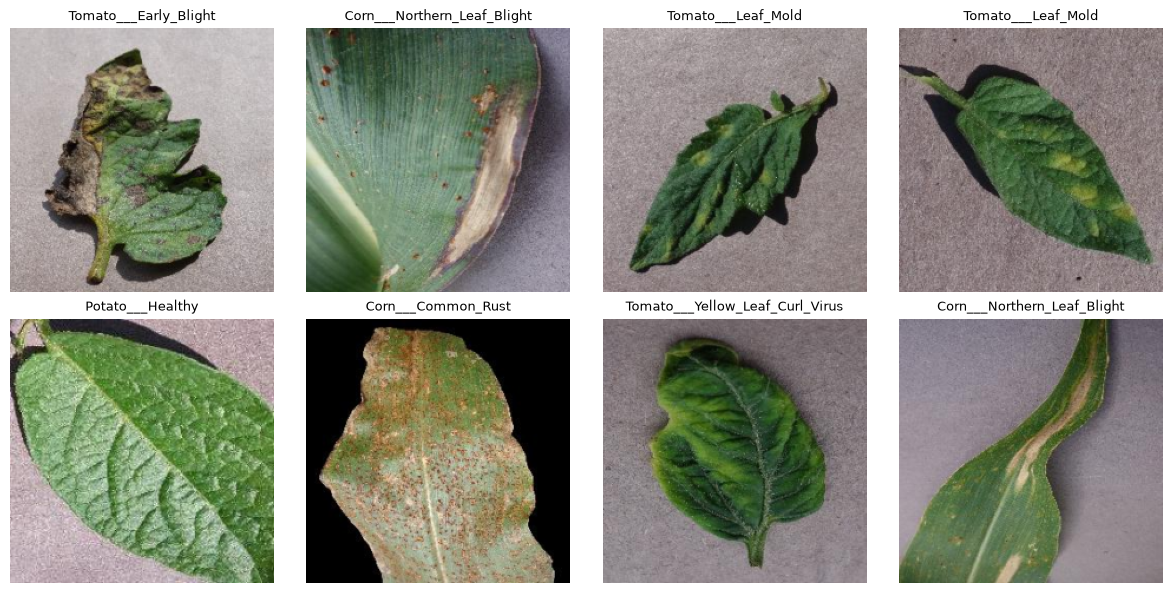

In [35]:
x, y = next(iter(loaders["train"]))

print("Batch shape :", tuple(x.shape), "| labels:", tuple(y.shape))
print("Value range : min %.2f  max %.2f" % (x.min(), x.max()))
print("Per-channel mean (should be ~0):", x.mean(dim=(0, 2, 3)).numpy().round(3))
print("Per-channel std  (should be ~1):", x.std(dim=(0, 2, 3)).numpy().round(3))

classes = json.loads((SPLIT_DIR / "meta.json").read_text())["classes"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, img, lab in zip(axes.ravel(), x[:8], y[:8]):
    
    ax.imshow(prep.denormalize(img).permute(1, 2, 0))
    ax.set_title(classes[lab], fontsize=9)
    ax.axis("off")
    
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "figures" / "preprocessed_samples.png", dpi=150)
plt.show()

In [36]:
SPLITS  = ["train", "val", "test"]
COLORS  = {"train": "#2a7fba", "val": "#f28e2b", "test": "#59a14f"}
CLASSES = json.loads((SPLIT_DIR / "meta.json").read_text())["classes"]

dfs = {s: pd.read_csv(SPLIT_DIR / f"{s}.csv") for s in SPLITS}

counts = pd.DataFrame({s: dfs[s]["label"].value_counts() for s in SPLITS}).reindex(CLASSES).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)

percent = counts[SPLITS].div(counts[SPLITS].sum(axis=0), axis=1) * 100

display(counts)
print("Images per split:", counts[SPLITS].sum().to_dict(), "| total:", int(counts["total"].sum()))

,train,val,test,total
label,,,,
Corn___Common_Rust,834,179,179,1192
Corn___Gray_Leaf_Spot,1120,240,240,1600
Corn___Healthy,813,175,174,1162
Corn___Northern_Leaf_Blight,2030,435,435,2900
Grape___Black_Measles,1590,340,341,2271
Grape___Black_Rot,826,177,177,1180
Grape___Healthy,914,196,195,1305
Grape___Leaf_Blight,753,162,161,1076
Potato___Early_Blight,700,150,150,1000


Images per split: {'train': 28156, 'val': 6033, 'test': 6034} | total: 40223


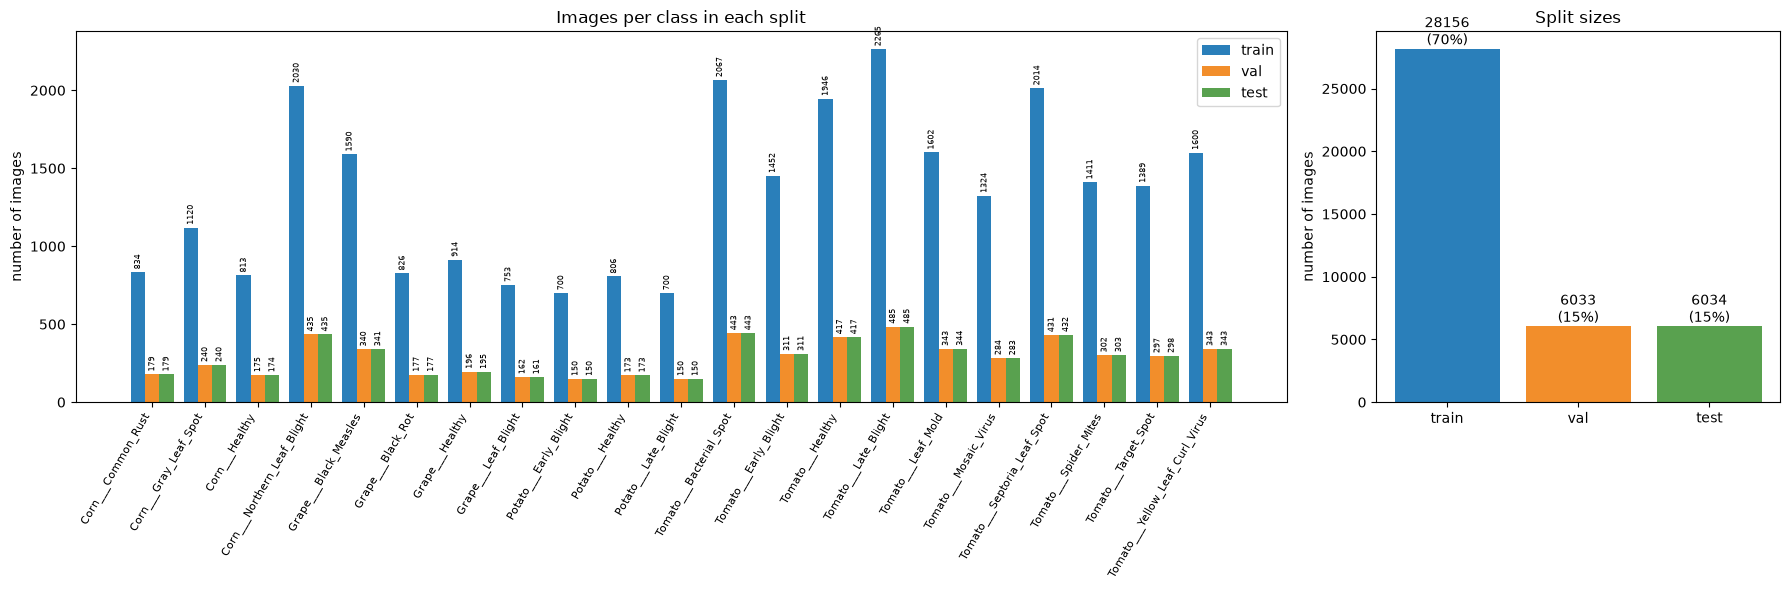

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [3, 1]})

x, w = np.arange(len(CLASSES)), 0.27
for i, s in enumerate(SPLITS):
    bars = axes[0].bar(x + (i - 1) * w, counts[s], w, label=s, color=COLORS[s])
    axes[0].bar_label(bars, fontsize=6, rotation=90, padding=2)    
    
axes[0].set_xticks(x)
axes[0].set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
axes[0].set_ylabel("number of images")
axes[0].set_title("Images per class in each split")
axes[0].legend()

sizes = counts[SPLITS].sum()
bars = axes[1].bar(SPLITS, sizes, color=[COLORS[s] for s in SPLITS])
axes[1].bar_label(bars, labels=[f"{v}\n({v / sizes.sum():.0%})" for v in sizes])
axes[1].set_title("Split sizes")
axes[1].set_ylabel("number of images")

plt.tight_layout()
plt.savefig(FIG_DIR / "split_class_counts.png", dpi=150)
plt.show()

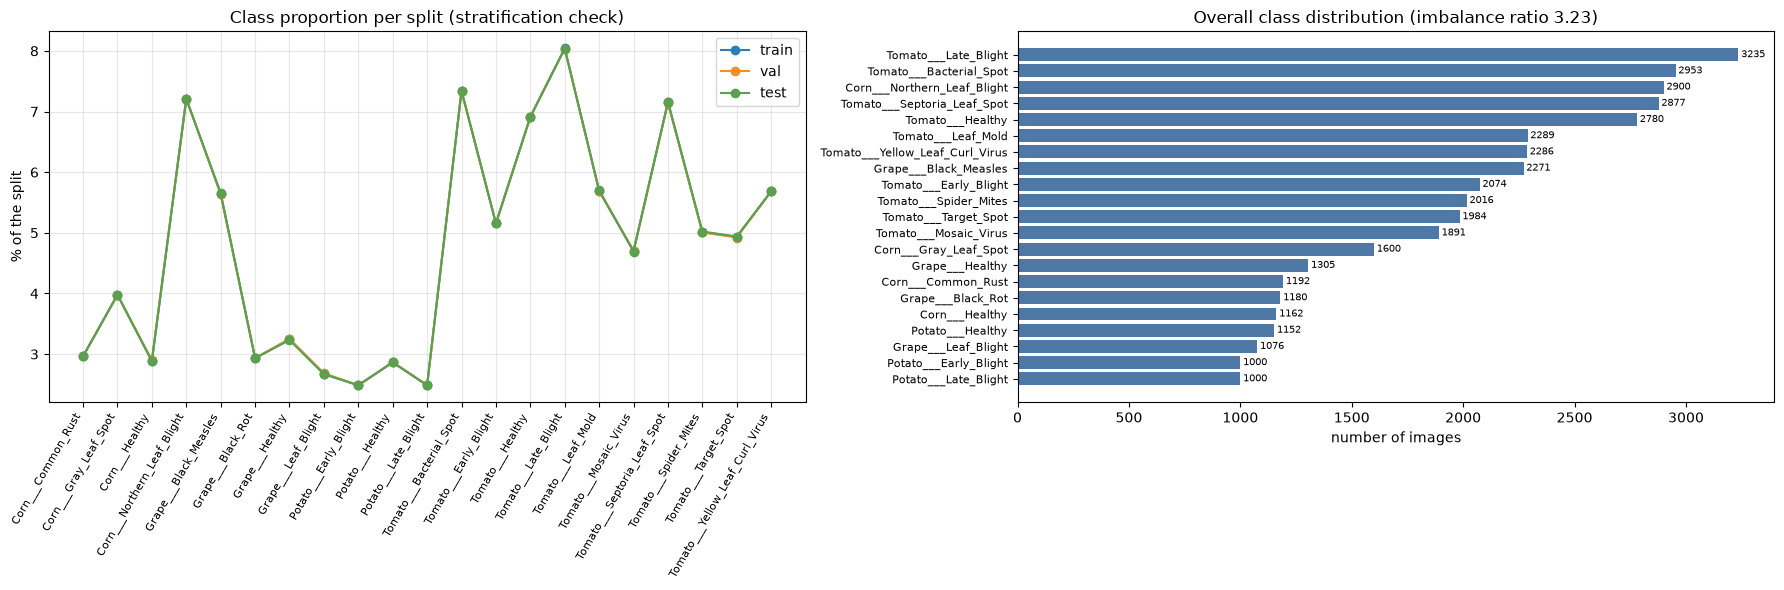

Max difference in class proportion between splits: 0.017 percentage points


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for s in SPLITS:
    axes[0].plot(CLASSES, percent[s], marker="o", label=s, color=COLORS[s])
axes[0].set_xticks(range(len(CLASSES)))
axes[0].set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
axes[0].set_ylabel("% of the split")
axes[0].set_title("Class proportion per split (stratification check)")
axes[0].legend()
axes[0].grid(alpha=0.3)

order = counts["total"].sort_values(ascending=True)
axes[1].barh(order.index, order.values, color="#4e79a7")
axes[1].bar_label(axes[1].containers[0], fontsize=7, padding=2)
axes[1].set_xlabel("number of images")
axes[1].set_title(f"Overall class distribution (imbalance ratio {order.max() / order.min():.2f})")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution_stratification.png", dpi=150)
plt.show()

gap = (percent[SPLITS].max(axis=1) - percent[SPLITS].min(axis=1)).max()
print(f"Max difference in class proportion between splits: {gap:.3f} percentage points")